[TTBarZJetsData] Dropping 876/230000 jets (0.381%) with < 10 valid constituents.


Building X(k=10):   0%|          | 0/114124 [00:00<?, ?it/s]

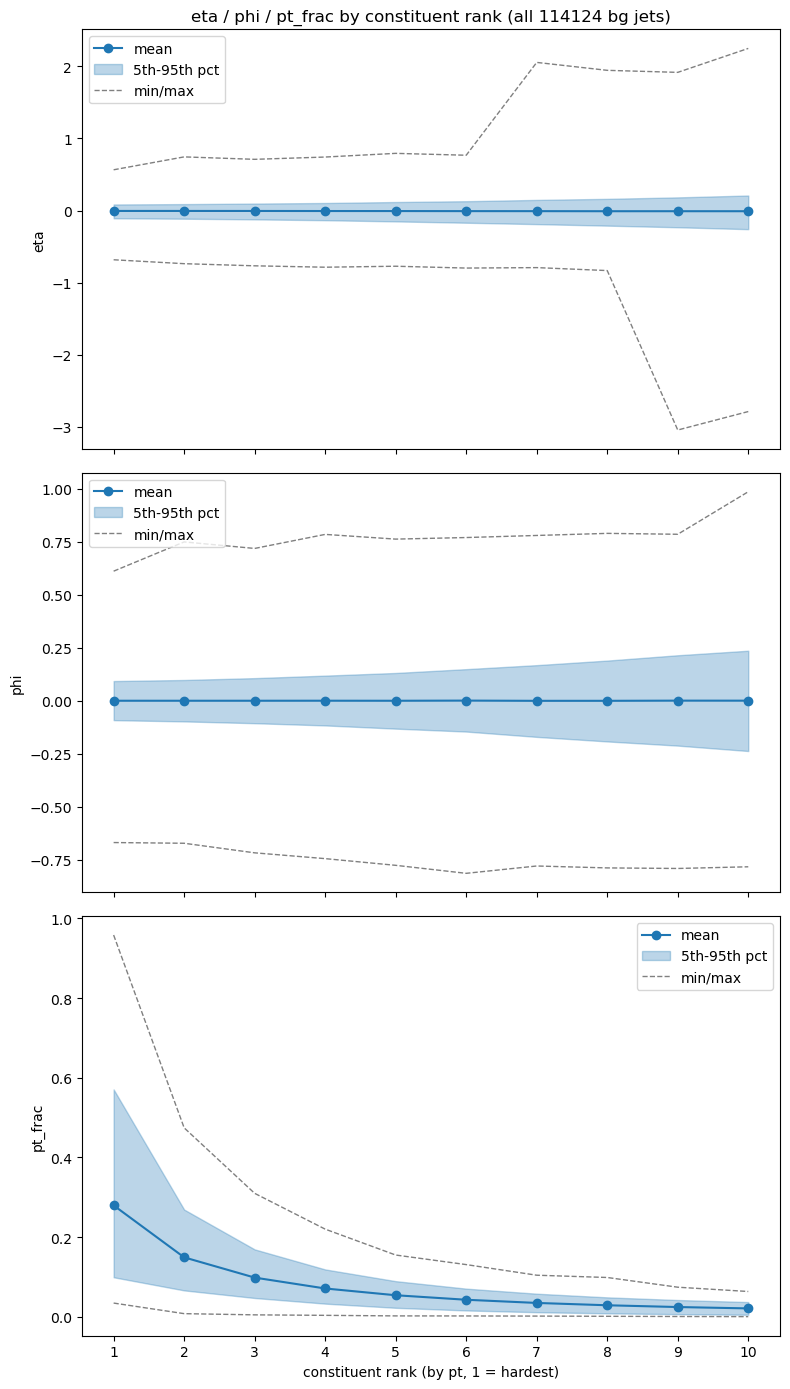

Building X(k=10):   0%|          | 0/114124 [00:00<?, ?it/s]

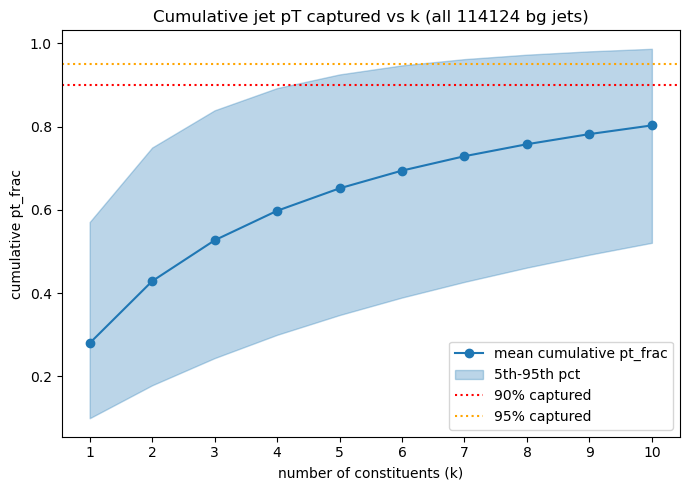

In [11]:
import matplotlib.pyplot as plt
import numpy as np
import sys
sys.path.append("/home/hep/lgc124/PhDCode/LXAutoQML/AutoQML/jointCode")  # wherever this class lives

from data_loader import TTBarZJetsData
from types import SimpleNamespace

cfg = SimpleNamespace(
    circuit=SimpleNamespace(wires=8),
    data=SimpleNamespace(train_num_samples=2, val_num_samples=0, test_num_samples=0),
)

data = TTBarZJetsData(cfg)

def plot_feature_dropoff_all_bg(data, k):
    """
    Per-rank stats (eta, phi, pt_frac) over ALL background jets
    (post multiplicity-filter, pre train/val/test split).
    """
    bg_idx = np.where(data.truth == data.truth.min())[0]

    X = data.build_X(data.const, data.jet_pt, bg_idx, k=k)
    eta, phi, pt_frac = X[:, :, 0], X[:, :, 1], X[:, :, 2]

    # real constituent present iff pt_frac > 0 (see build_X padding logic)
    valid = pt_frac > 0

    ranks = np.arange(1, k + 1)

    def stats(feat):
        mean = np.array([feat[valid[:, i], i].mean() for i in range(k)])
        p05  = np.array([np.percentile(feat[valid[:, i], i], 5)  for i in range(k)])
        p95  = np.array([np.percentile(feat[valid[:, i], i], 95) for i in range(k)])
        fmin = np.array([feat[valid[:, i], i].min() for i in range(k)])
        fmax = np.array([feat[valid[:, i], i].max() for i in range(k)])
        return mean, p05, p95, fmin, fmax

    eta_stats = stats(eta)
    phi_stats = stats(phi)
    pt_stats  = stats(pt_frac)
    frac_present = valid.mean(axis=0)

    fig, axes = plt.subplots(3, 1, figsize=(8, 14), sharex=True)

    for ax, (mean, p05, p95, fmin, fmax), label in zip(
        axes, [eta_stats, phi_stats, pt_stats], ["eta", "phi", "pt_frac"]
    ):
        ax.plot(ranks, mean, "o-", color="C0", label="mean")
        ax.fill_between(ranks, p05, p95, alpha=0.3, color="C0", label="5th-95th pct")
        ax.plot(ranks, fmin, "--", color="gray", lw=1, label="min/max")
        ax.plot(ranks, fmax, "--", color="gray", lw=1)
        ax.set_ylabel(label)
        ax.legend()

    axes[0].set_title(f"eta / phi / pt_frac by constituent rank (all {len(bg_idx)} bg jets)")
    axes[-1].set_xlabel("constituent rank (by pt, 1 = hardest)")
    axes[-1].set_xticks(ranks)

    plt.tight_layout()
    plt.savefig("feature_dropoff_all_bg.png", dpi=150)
    plt.show()

    return ranks, eta_stats, phi_stats, pt_stats, frac_present

ranks, eta_stats, phi_stats, pt_stats, frac_present = plot_feature_dropoff_all_bg(data, k=10)

def cumulative_pt_frac(data, k_max):
    bg_idx = np.where(data.truth == data.truth.min())[0]
    X = data.build_X(data.const, data.jet_pt, bg_idx, k=k_max)
    pt_frac = X[:, :, 2]  # (n_jets, k_max)

    cum = np.cumsum(pt_frac, axis=1)  # cumulative pt_frac per jet, per k
    mean_cum = cum.mean(axis=0)
    p05 = np.percentile(cum, 5, axis=0)
    p95 = np.percentile(cum, 95, axis=0)

    ks = np.arange(1, k_max + 1)
    fig, ax = plt.subplots(figsize=(7, 5))
    ax.plot(ks, mean_cum, "o-", color="C0", label="mean cumulative pt_frac")
    ax.fill_between(ks, p05, p95, alpha=0.3, color="C0", label="5th-95th pct")
    ax.axhline(0.9, ls=":", color="red", label="90% captured")
    ax.axhline(0.95, ls=":", color="orange", label="95% captured")
    ax.set_xlabel("number of constituents (k)")
    ax.set_ylabel("cumulative pt_frac")
    ax.set_xticks(ks)
    ax.legend()
    ax.set_title(f"Cumulative jet pT captured vs k (all {len(bg_idx)} bg jets)")
    plt.tight_layout()
    plt.savefig("cumulative_pt_frac.png", dpi=150)
    plt.show()

    return ks, mean_cum, p05, p95

ks, mean_cum, p05, p95 = cumulative_pt_frac(data,k_max=10)